In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/uciml/human-activity-recognition-with-smartphones/test.csv
/kaggle/input/datasets/uciml/human-activity-recognition-with-smartphones/train.csv


# 1.Imports

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.kernel_approximation import Nystroem
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 2. Load Data

In [3]:

train_df = pd.read_csv("/kaggle/input/datasets/uciml/human-activity-recognition-with-smartphones/train.csv")
test_df = pd.read_csv("/kaggle/input/datasets/uciml/human-activity-recognition-with-smartphones/test.csv")
df = pd.concat([train_df, test_df], ignore_index=True)

print(df.shape)
print(df["Activity"].value_counts())

(10299, 563)
Activity
LAYING                1944
STANDING              1906
SITTING               1777
WALKING               1722
WALKING_UPSTAIRS      1544
WALKING_DOWNSTAIRS    1406
Name: count, dtype: int64


# 3. Dataset, Stratified 80/20 Split and Scaling

In [4]:
X = df.drop(columns=["Activity", "subject"], errors="ignore").values
le = LabelEncoder()
y = le.fit_transform(df["Activity"])
n_classes = len(le.classes_)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print("train:", X_train.shape, "test:", X_test.shape, "classes:", n_classes)


train: (8239, 561) test: (2060, 561) classes: 6


# 4. Kernels (Linear, Polynomial, RBF)

In [5]:
def add_bias(A):
    return np.hstack([A, np.ones((A.shape[0], 1))])

def make_features(mapper=None):
    if mapper is None:
        A, B = X_train, X_test
    else:
        A, B = mapper.fit_transform(X_train), mapper.transform(X_test)
    s = StandardScaler()
    return add_bias(s.fit_transform(A)), add_bias(s.transform(B))

d = X_train.shape[1]
feats = {
    "Linear": make_features(None),
    "Polynomial": make_features(Nystroem(kernel="poly", degree=3, gamma=1.0/d, coef0=1,
                                         n_components=300, random_state=42)),
    "RBF": make_features(Nystroem(kernel="rbf", gamma=1.0/d,
                                  n_components=300, random_state=42)),
}
for k, (a, b) in feats.items():
    print(k, a.shape)

Linear (8239, 562)
Polynomial (8239, 301)
RBF (8239, 301)


# 5.SVM Multiclass Hinge Loss and Gradient

In [6]:
LAM = 1e-4

def loss_grad(W, X, y, lam=LAM):
    n = X.shape[0]
    scores = X @ W
    correct = scores[np.arange(n), y]
    margins = scores - correct[:, None] + 1
    margins[np.arange(n), y] = 0
    pos = margins > 0
    loss = margins[pos].sum() / n + 0.5 * lam * np.sum(W[:-1] ** 2)
    mask = pos.astype(float)
    mask[np.arange(n), y] = -pos.sum(axis=1)
    grad = X.T @ mask / n
    reg = lam * W
    reg[-1] = 0
    return loss, grad + reg

# 6. RMSprop

In [7]:
def rmsprop(Xtr, ytr, lr, epochs, bs, rho=0.9, eps=1e-8, seed=42):
    rng = np.random.default_rng(seed)
    W = np.zeros((Xtr.shape[1], n_classes))
    s = np.zeros_like(W)
    history = []
    for ep in range(epochs):
        idx = rng.permutation(Xtr.shape[0])
        for i in range(0, len(idx), bs):
            b = idx[i:i+bs]
            _, g = loss_grad(W, Xtr[b], ytr[b])
            s = rho * s + (1 - rho) * g * g
            W -= lr * g / (np.sqrt(s) + eps)
        history.append(loss_grad(W, Xtr, ytr)[0])
    return W, history

# 7. Evaluation Helpers

In [8]:
def softmax(s):
    e = np.exp(s - s.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

def metrics(y_true, pred, loss=np.nan):
    return dict(
        Accuracy=accuracy_score(y_true, pred),
        Precision=precision_score(y_true, pred, average="macro", zero_division=0),
        Recall=recall_score(y_true, pred, average="macro", zero_division=0),
        F1=f1_score(y_true, pred, average="macro", zero_division=0),
        Loss=loss)

# 8. Train SVM with RMSprop (3 Kernels) and Test Metrics

In [9]:
LR, EPOCHS, BS = 0.001, 30, 64
results, scores_test, histories = {}, {}, {}

for k, (Ztr, Zte) in feats.items():
    t0 = time.time()
    W, hist = rmsprop(Ztr, y_train, LR, EPOCHS, BS)
    scores = Zte @ W
    scores_test[k] = scores
    histories[k] = hist
    results[f"SVM ({k})"] = metrics(y_test, scores.argmax(axis=1), loss=hist[-1])
    print(f"{k} done in {time.time()-t0:.1f}s")

pd.DataFrame(results).T.round(4)

Linear done in 1.8s
Polynomial done in 1.2s
RBF done in 1.3s


,Accuracy,Precision,Recall,F1,Loss
SVM (Linear),0.9772,0.9789,0.9771,0.9777,0.0468
SVM (Polynomial),0.9709,0.9715,0.9721,0.9718,0.0465
SVM (RBF),0.9665,0.9669,0.9674,0.9670,0.0566


# 9. Voting (Hard and Soft)

In [10]:
ks = list(scores_test.keys())

preds = np.vstack([scores_test[k].argmax(axis=1) for k in ks])
hard = np.array([np.bincount(preds[:, i], minlength=n_classes).argmax()
                 for i in range(preds.shape[1])])

soft = np.mean([softmax(scores_test[k]) for k in ks], axis=0).argmax(axis=1)

results["Hard Voting"] = metrics(y_test, hard)
results["Soft Voting"] = metrics(y_test, soft)

# 10. GD Final Results Table

In [11]:
res_df = pd.DataFrame(results).T.round(4)
res_df

,Accuracy,Precision,Recall,F1,Loss
SVM (Linear),0.9772,0.9789,0.9771,0.9777,0.0468
SVM (Polynomial),0.9709,0.9715,0.9721,0.9718,0.0465
SVM (RBF),0.9665,0.9669,0.9674,0.9670,0.0566
Hard Voting,0.9738,0.9747,0.9750,0.9748,NaN
Soft Voting,0.9791,0.9802,0.9800,0.9800,NaN


# 11. Loss Curves

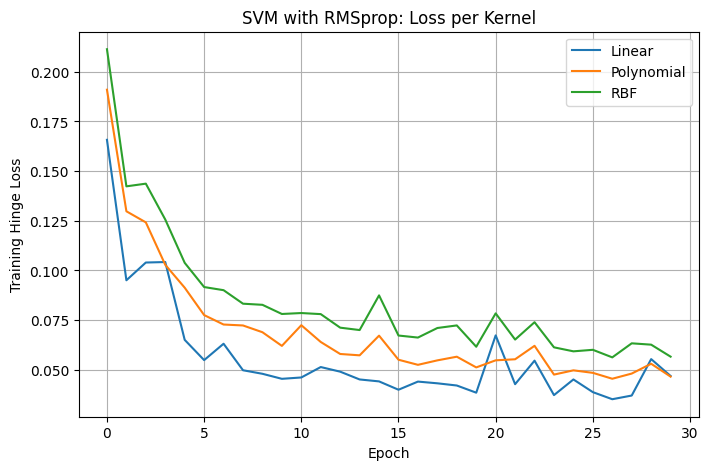

In [12]:
plt.figure(figsize=(8, 5))
for k, h in histories.items():
    plt.plot(h, label=k)
plt.xlabel("Epoch")
plt.ylabel("Training Hinge Loss")
plt.title("SVM with RMSprop: Loss per Kernel")
plt.legend()
plt.grid(True)
plt.show()